# MODIS Heat Dataset — Corrected Experiment Notebook

**Project:** Integrated Urban Risk Analytics and Resource Prioritization System  
**Dataset:** `hyderabad_modis_heat.csv`  
**Records expected:** 1,326 spatial samples

This notebook preserves the useful work from the original MODIS notebook and adds reproducible, corrected experiments.

## What this notebook does

1. Load and audit the actual MODIS dataset.
2. Explore temperature distributions and spatial patterns.
3. Reproduce the original four-feature, seven-cluster K-Means experiment.
4. Audit the original manual Low/Medium/High cluster mapping without treating it as ground truth.
5. Compare spatial-plus-thermal clustering with temperature-only clustering.
6. Run supervised **regression** using a measured temperature column as the target, with spatially separated validation.
7. Run an optional supervised classifier experiment that learns to reproduce K-Means cluster assignments. This is explicitly an imitation experiment, **not independent heat-risk classification**.
8. Save a regression model candidate only when it beats a simple baseline on the held-out spatial test set.

> **Scientific boundary:** The source dataset has no independently verified heat-risk class and no exact observation date in the processed table. Therefore, this notebook does not claim to predict current temperature, future temperature, or validated heat risk. The regression task is a cross-variable estimate of the measured daytime temperature from the nighttime measurement and coordinates.

## Important

- Keep the original `MODIS ALL ALGORITHMS.ipynb` unchanged.
- Run this corrected notebook from the project workspace in VS Code.
- The code uses the project's `data/processed/heat/hyderabad_modis_heat.csv` file.
- Cluster numbers are arbitrary identifiers; they must not be interpreted as an ordered heat scale.

## 1. Import libraries and locate the dataset

In [18]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# Set the actual project folder
PROJECT_ROOT = Path(
    r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics"
)

# Locate the MODIS dataset
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "heat"
    / "hyderabad_modis_heat.csv"
)

# Verify the paths
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_ROOT}"
    )

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"MODIS CSV not found: {DATA_PATH}"
    )

# Output folder for experiment results
OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "heat"
    / "modis_experiments"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Load dataset
modis = pd.read_csv(DATA_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset shape:", modis.shape)

display(modis.head())

Project root: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Dataset path: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_modis_heat.csv
Dataset shape: (1326, 5)


,pixel_id,latitude,longitude,daytime_temp_c,nighttime_temp_c
0,0,17.252145,78.301652,36.602941,20.399730
1,1,17.252145,78.310635,37.113429,20.463514
2,2,17.252145,78.319618,37.561429,20.448333
3,3,17.252145,78.328601,37.337429,20.488919
4,4,17.252145,78.337584,36.722571,20.528919


## 2. Data-quality audit

In [19]:
required_columns = [
    "pixel_id",
    "latitude",
    "longitude",
    "daytime_temp_c",
    "nighttime_temp_c"
]

missing_columns = [column for column in required_columns if column not in modis.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Data types:")
display(modis[required_columns].dtypes.to_frame("dtype"))

print("Missing values:")
display(modis[required_columns].isna().sum().to_frame("missing_count"))

numeric_columns = modis[required_columns].select_dtypes(include=np.number).columns
infinite_counts = np.isinf(modis[numeric_columns]).sum()
print("Infinite values:")
display(infinite_counts.to_frame("infinite_count"))

print("Duplicate rows:", modis.duplicated().sum())
print("Duplicate pixel IDs:", modis["pixel_id"].duplicated().sum())

if modis[required_columns].isna().any().any():
    raise ValueError("Missing values found in required columns. Resolve before modelling.")
if np.isinf(modis[numeric_columns].to_numpy()).any():
    raise ValueError("Infinite values found. Resolve before modelling.")
if modis["pixel_id"].duplicated().any():
    raise ValueError("Duplicate pixel IDs found. Investigate before modelling.")

print("\nData-quality checks passed.")
display(modis[required_columns].describe().T)

Data types:


,dtype
pixel_id,int64
latitude,float64
longitude,float64
daytime_temp_c,float64
nighttime_temp_c,float64


Missing values:


,missing_count
pixel_id,0
latitude,0
longitude,0
daytime_temp_c,0
nighttime_temp_c,0


Infinite values:


,infinite_count
pixel_id,0
latitude,0
longitude,0
daytime_temp_c,0
nighttime_temp_c,0


Duplicate rows: 0
Duplicate pixel IDs: 0

Data-quality checks passed.


,count,mean,std,min,25%,50%,75%,max
pixel_id,1326.0,662.500000,382.927539,0.000000,331.250000,662.500000,993.750000,1325.000000
latitude,1326.0,17.400367,0.088164,17.252145,17.324010,17.400367,17.476724,17.548589
longitude,1326.0,78.472332,0.101140,78.301652,78.382500,78.472332,78.562163,78.643012
daytime_temp_c,1326.0,34.323556,1.299366,26.644737,33.789167,34.312162,34.978026,37.593243
nighttime_temp_c,1326.0,22.473464,1.225156,19.846757,21.442143,22.412270,23.442500,25.210000


## 3. Exploratory data analysis

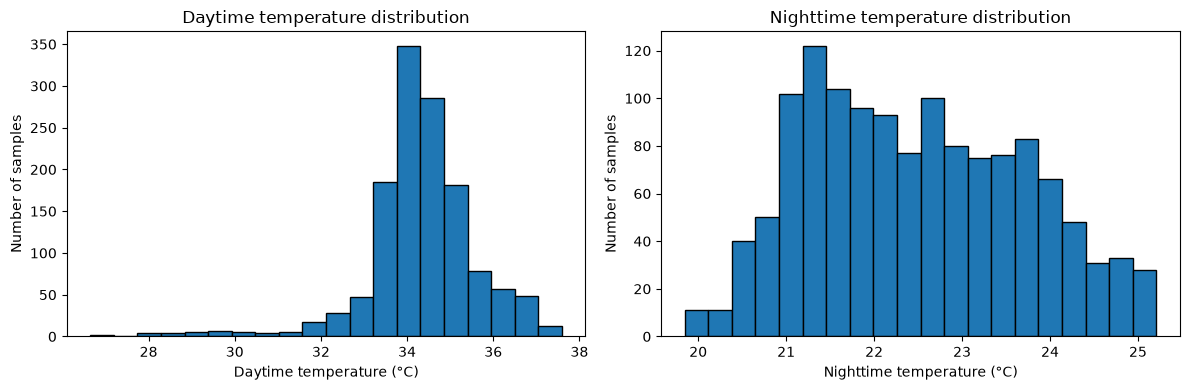

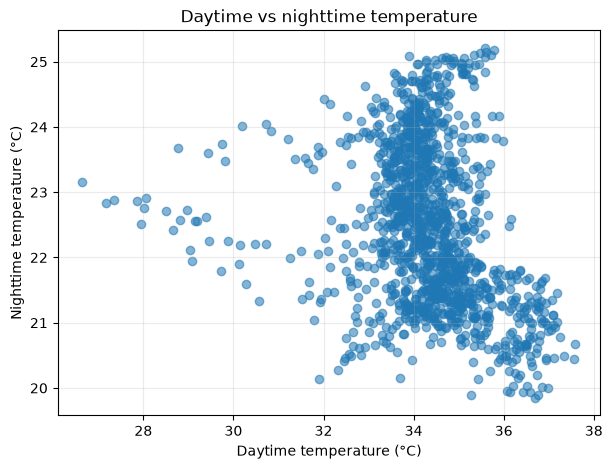

Temperature correlation:


,daytime_temp_c,nighttime_temp_c
daytime_temp_c,1.000000,-0.274216
nighttime_temp_c,-0.274216,1.000000


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(modis["daytime_temp_c"], bins=20, edgecolor="black")
axes[0].set_title("Daytime temperature distribution")
axes[0].set_xlabel("Daytime temperature (°C)")
axes[0].set_ylabel("Number of samples")

axes[1].hist(modis["nighttime_temp_c"], bins=20, edgecolor="black")
axes[1].set_title("Nighttime temperature distribution")
axes[1].set_xlabel("Nighttime temperature (°C)")
axes[1].set_ylabel("Number of samples")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(modis["daytime_temp_c"], modis["nighttime_temp_c"], alpha=0.55)
plt.xlabel("Daytime temperature (°C)")
plt.ylabel("Nighttime temperature (°C)")
plt.title("Daytime vs nighttime temperature")
plt.grid(alpha=0.25)
plt.show()

print("Temperature correlation:")
display(modis[["daytime_temp_c", "nighttime_temp_c"]].corr())

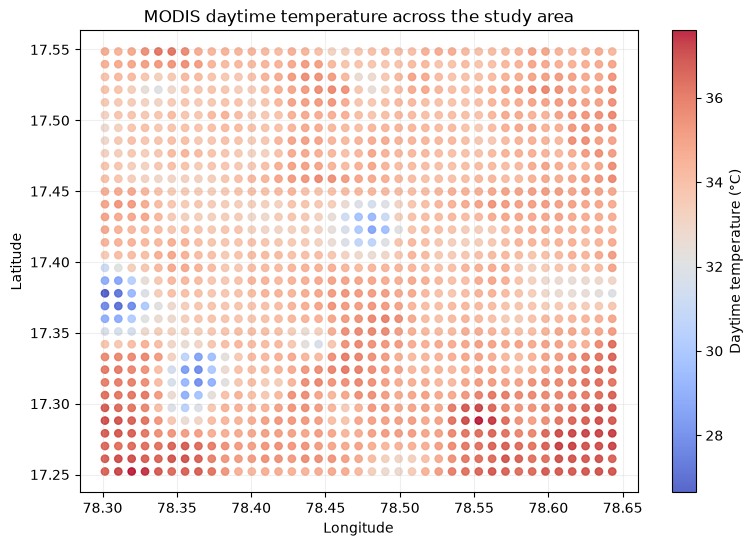

In [21]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    modis["longitude"],
    modis["latitude"],
    c=modis["daytime_temp_c"],
    cmap="coolwarm",
    s=28,
    alpha=0.85
)
plt.colorbar(scatter, label="Daytime temperature (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("MODIS daytime temperature across the study area")
plt.grid(alpha=0.2)
plt.show()

## 4. Reproduce the original four-feature K-Means experiment

The original notebook used four scaled features and `KMeans(n_clusters=7, n_init=10, random_state=42)`. The following cell reproduces that configuration for an unsupervised spatial/thermal exploration.

**Note:** Scaling is fitted to the complete dataset here because this is an exploratory unsupervised analysis, not a supervised holdout evaluation. The supervised regression section below uses train-only preprocessing.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

spatial_thermal_features = [
    "latitude",
    "longitude",
    "daytime_temp_c",
    "nighttime_temp_c"
]

X_spatial_thermal = modis[spatial_thermal_features].copy()
scaler_spatial_thermal = StandardScaler()
X_spatial_thermal_scaled = scaler_spatial_thermal.fit_transform(X_spatial_thermal)

kmeans_spatial_thermal = KMeans(
    n_clusters=7,
    n_init=10,
    random_state=RANDOM_STATE
)

modis_clustered = modis.copy()
modis_clustered["Cluster"] = kmeans_spatial_thermal.fit_predict(
    X_spatial_thermal_scaled
)

print("Cluster counts:")
display(modis_clustered["Cluster"].value_counts().sort_index().to_frame("sample_count"))

print("Inertia:", round(kmeans_spatial_thermal.inertia_, 3))
print("Silhouette score:", round(
    silhouette_score(X_spatial_thermal_scaled, modis_clustered["Cluster"]), 4
))

Cluster counts:


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,sample_count
Cluster,
0,133
1,301
2,51
3,329
4,201
5,65
6,246


Inertia: 1394.9
Silhouette score: 0.3553


## 5. Inspect cluster temperature and geographical profiles

,sample_count,mean_latitude,mean_longitude,daytime_mean_c,daytime_median_c,nighttime_mean_c,nighttime_median_c
Cluster,,,,,,,
5,65,17.284,78.333,36.161,36.191,20.548,20.496
0,133,17.294,78.595,36.000,36.139,21.281,21.246
6,246,17.474,78.587,34.324,34.399,21.640,21.536
4,201,17.304,78.426,34.297,34.411,21.829,21.804
3,329,17.403,78.496,34.223,34.203,24.056,24.038
1,301,17.480,78.377,34.019,33.921,22.787,22.817
2,51,17.364,78.370,30.162,30.194,22.538,22.557


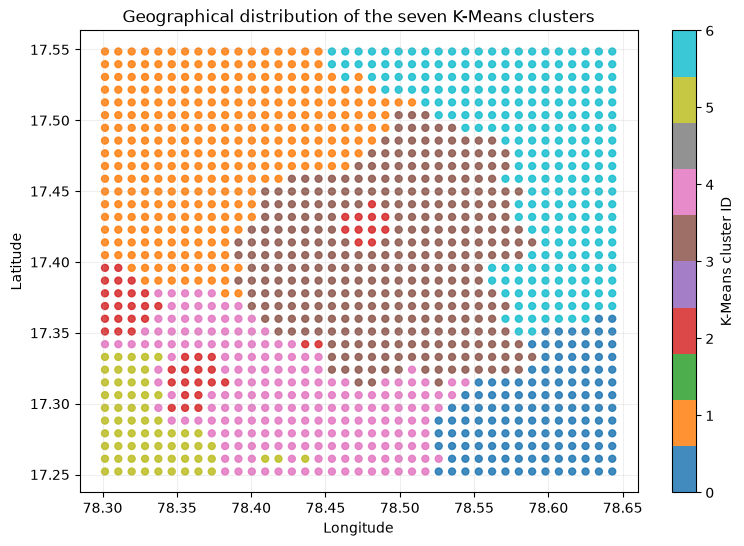

In [23]:
cluster_profile = (
    modis_clustered.groupby("Cluster")
    .agg(
        sample_count=("pixel_id", "count"),
        mean_latitude=("latitude", "mean"),
        mean_longitude=("longitude", "mean"),
        daytime_mean_c=("daytime_temp_c", "mean"),
        daytime_median_c=("daytime_temp_c", "median"),
        nighttime_mean_c=("nighttime_temp_c", "mean"),
        nighttime_median_c=("nighttime_temp_c", "median"),
    )
    .round(3)
    .sort_values("daytime_mean_c", ascending=False)
)

display(cluster_profile)
cluster_profile.to_csv(OUTPUT_DIR / "modis_spatial_thermal_cluster_profile.csv")

# Cluster number is a nominal identifier. It is not a low-to-high ranking.
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    modis_clustered["longitude"],
    modis_clustered["latitude"],
    c=modis_clustered["Cluster"],
    cmap="tab10",
    s=25,
    alpha=0.85
)
plt.colorbar(scatter, label="K-Means cluster ID")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical distribution of the seven K-Means clusters")
plt.grid(alpha=0.2)
plt.show()

## 6. PCA dimensionality reduction (original experiment)

PCA is retained from the original notebook. It projects the four standardized spatial/thermal features into two principal components for visual exploration. PCA components are combinations of the input features; they are not new measured temperature variables.

PCA output shape: (1326, 3)
Explained variance ratio: [0.40775483 0.26281264]
Total explained variance: 0.6706


,PC1,PC2,Cluster
0,2.173654,-2.282506,5
1,2.413075,-2.110272,5
2,2.657639,-1.968202,5
3,2.568006,-1.927597,5
4,2.298206,-1.954141,5


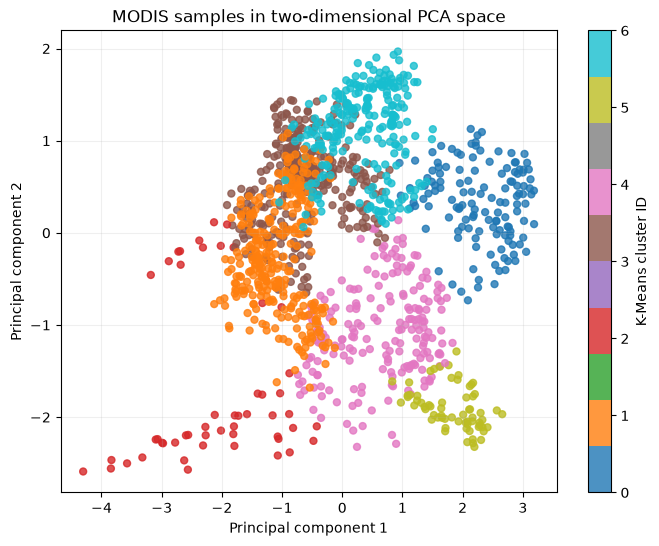

In [24]:
from sklearn.decomposition import PCA

pca_modis = PCA(n_components=2)
X_modis_pca = pca_modis.fit_transform(X_spatial_thermal_scaled)

pca_modis_df = pd.DataFrame(X_modis_pca, columns=["PC1", "PC2"])
pca_modis_df["Cluster"] = modis_clustered["Cluster"].to_numpy()

print("PCA output shape:", pca_modis_df.shape)
print("Explained variance ratio:", pca_modis.explained_variance_ratio_)
print("Total explained variance:", round(pca_modis.explained_variance_ratio_.sum(), 4))
display(pca_modis_df.head())

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    pca_modis_df["PC1"], pca_modis_df["PC2"],
    c=pca_modis_df["Cluster"], cmap="tab10", s=25, alpha=0.8
)
plt.colorbar(scatter, label="K-Means cluster ID")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("MODIS samples in two-dimensional PCA space")
plt.grid(alpha=0.2)
plt.show()

## 6. Audit the original manually assigned Low/Medium/High mapping

The original notebook manually mapped the seven cluster IDs to `Low`, `Medium`, and `High`. The original mapping is reproduced below **only for audit and comparison**.

It is not independent ground truth. Cluster numbers can change when the data, scaling, row order, or model configuration changes. The resulting category names must therefore be described as exploratory pseudo-labels, not verified heat-risk classes.

In [25]:
original_cluster_mapping = {
    2: "Low",
    6: "Low",
    4: "Low",
    5: "Medium",
    1: "Medium",
    0: "High",
    3: "High"
}

legacy_label_audit = modis_clustered.copy()
legacy_label_audit["Original_Category"] = legacy_label_audit["Cluster"].map(
    original_cluster_mapping
)

legacy_category_profile = (
    legacy_label_audit.groupby("Original_Category")
    .agg(
        sample_count=("pixel_id", "count"),
        daytime_mean_c=("daytime_temp_c", "mean"),
        daytime_median_c=("daytime_temp_c", "median"),
        nighttime_mean_c=("nighttime_temp_c", "mean"),
        nighttime_median_c=("nighttime_temp_c", "median")
    )
    .reindex(["Low", "Medium", "High"])
    .round(3)
)

display(legacy_category_profile)
legacy_category_profile.to_csv(OUTPUT_DIR / "modis_legacy_category_profile.csv")

print(
    "Interpretation: this table checks the original mapping's aggregate temperature ordering. "
    "Ordered means alone do not validate these labels as heat-risk ground truth."
)

,sample_count,daytime_mean_c,daytime_median_c,nighttime_mean_c,nighttime_median_c
Original_Category,,,,,
Low,498,33.887,34.278,21.808,21.696
Medium,366,34.399,34.129,22.389,22.609
High,462,34.735,34.463,23.257,23.730


Interpretation: this table checks the original mapping's aggregate temperature ordering. Ordered means alone do not validate these labels as heat-risk ground truth.


## 7. Compare spatial-plus-thermal clustering with temperature-only clustering

Two feature spaces are compared:

- **Spatial + thermal:** latitude, longitude, daytime temperature, nighttime temperature.
- **Thermal only:** daytime temperature and nighttime temperature.

For each feature space, K-Means is evaluated for `k = 2` through `10`. Silhouette score and inertia are descriptive clustering metrics. Because the feature spaces differ, use the scores alongside cluster sizes, temperature profiles, and maps; do not select a model from silhouette score alone.

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window


Spatial_Thermal — seven-cluster profile


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,sample_count,daytime_mean_c,nighttime_mean_c,mean_latitude,mean_longitude
Cluster,,,,,
5,65,36.161,20.548,17.284,78.333
0,133,36.000,21.281,17.294,78.595
6,246,34.324,21.640,17.474,78.587
4,201,34.297,21.829,17.304,78.426
3,329,34.223,24.056,17.403,78.496
1,301,34.019,22.787,17.480,78.377
2,51,30.162,22.538,17.364,78.370


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window


Thermal_Only — seven-cluster profile


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,sample_count,daytime_mean_c,nighttime_mean_c,mean_latitude,mean_longitude
Cluster,,,,,
2,156,36.342,20.953,17.289,78.493
3,304,34.755,21.495,17.403,78.519
6,168,34.573,24.442,17.392,78.484
1,303,34.331,22.719,17.431,78.451
4,223,33.616,23.606,17.444,78.445
0,138,33.145,21.513,17.402,78.448
5,34,29.333,22.757,17.368,78.374


,approach,n_clusters,inertia,silhouette_score
5,Spatial_Thermal,7,1394.900286,0.355259
6,Spatial_Thermal,8,1263.609183,0.345966
4,Spatial_Thermal,6,1575.656000,0.344800
7,Spatial_Thermal,9,1138.828128,0.340686
3,Spatial_Thermal,5,1901.599638,0.337193
8,Spatial_Thermal,10,1025.532941,0.326855
2,Spatial_Thermal,4,2307.693593,0.316083
1,Spatial_Thermal,3,2920.813854,0.300689
0,Spatial_Thermal,2,3742.819711,0.298313
10,Thermal_Only,3,1052.599340,0.449173


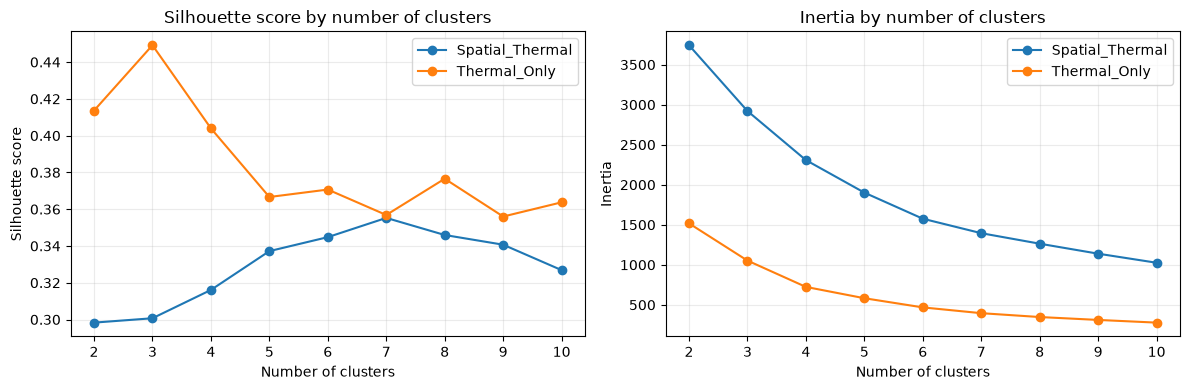

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feature_sets = {
    "Spatial_Thermal": [
        "latitude", "longitude", "daytime_temp_c", "nighttime_temp_c"
    ],
    "Thermal_Only": [
        "daytime_temp_c", "nighttime_temp_c"
    ]
}

cluster_comparison_rows = []
cluster_models = {}
cluster_labels_by_approach = {}
cluster_scalers = {}

for approach_name, feature_columns in feature_sets.items():
    X = modis[feature_columns].copy()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    cluster_scalers[approach_name] = scaler

    for k in range(2, 11):
        model = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=RANDOM_STATE
        )
        labels = model.fit_predict(X_scaled)
        cluster_comparison_rows.append({
            "approach": approach_name,
            "n_clusters": k,
            "inertia": model.inertia_,
            "silhouette_score": silhouette_score(X_scaled, labels)
        })

    final_model = KMeans(
        n_clusters=7,
        n_init=10,
        random_state=RANDOM_STATE
    )
    final_labels = final_model.fit_predict(X_scaled)
    cluster_models[approach_name] = final_model
    cluster_labels_by_approach[approach_name] = final_labels

    approach_profile = modis.copy()
    approach_profile["Cluster"] = final_labels
    profile = (
        approach_profile.groupby("Cluster")
        .agg(
            sample_count=("pixel_id", "count"),
            daytime_mean_c=("daytime_temp_c", "mean"),
            nighttime_mean_c=("nighttime_temp_c", "mean"),
            mean_latitude=("latitude", "mean"),
            mean_longitude=("longitude", "mean")
        )
        .round(3)
        .sort_values("daytime_mean_c", ascending=False)
    )
    print(f"\n{approach_name} — seven-cluster profile")
    display(profile)
    profile.to_csv(OUTPUT_DIR / f"{approach_name.lower()}_k7_profile.csv")

cluster_comparison = pd.DataFrame(cluster_comparison_rows)
display(cluster_comparison.sort_values(
    ["approach", "silhouette_score"], ascending=[True, False]
))
cluster_comparison.to_csv(OUTPUT_DIR / "modis_kmeans_approach_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for approach_name, group in cluster_comparison.groupby("approach"):
    axes[0].plot(group["n_clusters"], group["silhouette_score"], marker="o", label=approach_name)
    axes[1].plot(group["n_clusters"], group["inertia"], marker="o", label=approach_name)
axes[0].set_title("Silhouette score by number of clusters")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette score")
axes[1].set_title("Inertia by number of clusters")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Inertia")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Supervised regression: predict a measured temperature variable

The source data has measured temperature columns but no independent heat-risk target. A defensible supervised task available from this table is:

- **Target (`y`):** `daytime_temp_c` (a measured value in °C).
- **Features (`X`):** `latitude`, `longitude`, and `nighttime_temp_c`.

This estimates the observed daytime temperature from spatial position and the paired nighttime measurement. It is a **cross-variable regression experiment**, not a future-temperature forecast and not a heat-risk classifier.

### Spatial validation

Nearby grid samples can be highly correlated. A random row split can put neighbouring samples in both training and test sets. We therefore create geographic blocks and hold out whole blocks for the final test set. Hyperparameter tuning uses `GroupKFold` over the training blocks only. The scaler is inside each model pipeline so it is fitted within each training fold.

In [27]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV

TARGET_COLUMN = "daytime_temp_c"
REGRESSION_FEATURES = ["latitude", "longitude", "nighttime_temp_c"]

X_reg = modis[REGRESSION_FEATURES].copy()
y_reg = modis[TARGET_COLUMN].copy()

# Geographic block size is an explicit validation design choice.
# 0.04 degrees is approximately 4.4 km in latitude near Hyderabad.
SPATIAL_BLOCK_DEGREES = 0.04

lat_block = np.floor(
    (modis["latitude"] - modis["latitude"].min()) / SPATIAL_BLOCK_DEGREES
).astype(int)
lon_block = np.floor(
    (modis["longitude"] - modis["longitude"].min()) / SPATIAL_BLOCK_DEGREES
).astype(int)
spatial_groups = lat_block.astype(str) + "_" + lon_block.astype(str)

print("Unique spatial blocks:", spatial_groups.nunique())
print("Block size in degrees:", SPATIAL_BLOCK_DEGREES)

if spatial_groups.nunique() < 6:
    raise ValueError(
        "Too few geographic blocks for the planned spatial holdout and 5-fold GroupKFold. "
        "Review SPATIAL_BLOCK_DEGREES."
    )

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)
train_indices, test_indices = next(
    group_splitter.split(X_reg, y_reg, groups=spatial_groups)
)

X_train = X_reg.iloc[train_indices].copy()
X_test = X_reg.iloc[test_indices].copy()
y_train = y_reg.iloc[train_indices].copy()
y_test = y_reg.iloc[test_indices].copy()
groups_train = spatial_groups.iloc[train_indices]
groups_test = spatial_groups.iloc[test_indices]

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training spatial blocks:", groups_train.nunique())
print("Held-out spatial blocks:", groups_test.nunique())
print("Overlap in spatial blocks:", len(set(groups_train) & set(groups_test)))

assert len(set(groups_train) & set(groups_test)) == 0, "Spatial leakage: block overlap detected."

display(pd.DataFrame({
    "partition": ["train", "test"],
    "rows": [len(X_train), len(X_test)],
    "spatial_blocks": [groups_train.nunique(), groups_test.nunique()],
    "mean_daytime_temp_c": [y_train.mean(), y_test.mean()]
}))

Unique spatial blocks: 72
Block size in degrees: 0.04
Training rows: 1031
Test rows: 295
Training spatial blocks: 57
Held-out spatial blocks: 15
Overlap in spatial blocks: 0


,partition,rows,spatial_blocks,mean_daytime_temp_c
0,train,1031,57,34.390854
1,test,295,15,34.088354


## 9. Compare supervised regression algorithms with spatial cross-validation

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regression_models = {
    "Linear Regression": (
        LinearRegression(),
        {}
    ),
    "Ridge Regression": (
        Ridge(),
        {"model__alpha": [0.1, 1.0, 10.0, 100.0]}
    ),
    "Lasso Regression": (
        Lasso(max_iter=20000),
        {"model__alpha": [0.001, 0.01, 0.1, 1.0]}
    ),
    "Decision Tree Regressor": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {
            "model__max_depth": [None, 4, 8, 12],
            "model__min_samples_leaf": [1, 3, 5]
        }
    ),
    "Random Forest Regressor": (
        RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "model__max_depth": [None, 8, 15],
            "model__min_samples_leaf": [1, 3, 5],
            "model__max_features": [0.8, 1.0]
        }
    ),
    "Gradient Boosting Regressor": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.1],
            "model__max_depth": [2, 3]
        }
    ),
    "SVR": (
        SVR(),
        {
            "model__C": [1, 10, 100],
            "model__epsilon": [0.05, 0.1, 0.2],
            "model__kernel": ["rbf"]
        }
    )
}

n_splits = min(5, groups_train.nunique())
group_cv = GroupKFold(n_splits=n_splits)

search_results = []
best_estimators = {}

for model_name, (estimator, parameter_grid) in regression_models.items():
    print(f"Running spatial CV for: {model_name}")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="neg_mean_absolute_error",
        cv=group_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train, groups=groups_train)
    best_estimators[model_name] = search.best_estimator_

    search_results.append({
        "algorithm": model_name,
        "spatial_cv_mae_c": -search.best_score_,
        "best_parameters": str(search.best_params_)
    })

cv_results = pd.DataFrame(search_results).sort_values("spatial_cv_mae_c")
display(cv_results)
cv_results.to_csv(OUTPUT_DIR / "modis_regression_spatial_cv_results.csv", index=False)
# Select the model with the lowest spatial cross-validation MAE
best_algorithm_name = cv_results.iloc[0]["algorithm"]
best_regression_model = best_estimators[best_algorithm_name]

print("Selected algorithm:", best_algorithm_name)
print("Spatial CV MAE:", cv_results.iloc[0]["spatial_cv_mae_c"])

Running spatial CV for: Linear Regression
Running spatial CV for: Ridge Regression
Running spatial CV for: Lasso Regression
Running spatial CV for: Decision Tree Regressor
Running spatial CV for: Random Forest Regressor
Running spatial CV for: Gradient Boosting Regressor
Running spatial CV for: SVR


,algorithm,spatial_cv_mae_c,best_parameters
4,Random Forest Regressor,0.505722,"{'model__max_depth': 15, 'model__max_features'..."
6,SVR,0.560293,"{'model__C': 1, 'model__epsilon': 0.2, 'model_..."
3,Decision Tree Regressor,0.592547,"{'model__max_depth': 12, 'model__min_samples_l..."
5,Gradient Boosting Regressor,0.606739,"{'model__learning_rate': 0.03, 'model__max_dep..."
1,Ridge Regression,0.684764,{'model__alpha': 100.0}
2,Lasso Regression,0.690357,{'model__alpha': 0.01}
0,Linear Regression,0.691511,{}


Selected algorithm: Random Forest Regressor
Spatial CV MAE: 0.5057216703141942


## 10. Select using training-only spatial cross-validation; evaluate once on held-out spatial blocks

Selected algorithm from spatial CV: Random Forest Regressor
Spatial CV MAE (°C): 0.5057


,model,test_MAE_C,test_RMSE_C,test_R2
0,Random Forest Regressor,0.9493,1.3599,0.3566
1,Dummy mean baseline,1.2048,1.7222,-0.0318



Held-out spatial test set summary:
Target mean (°C): 34.088
Target standard deviation (°C): 1.698
Selected-model MAE (°C): 0.949
Baseline MAE (°C): 1.205


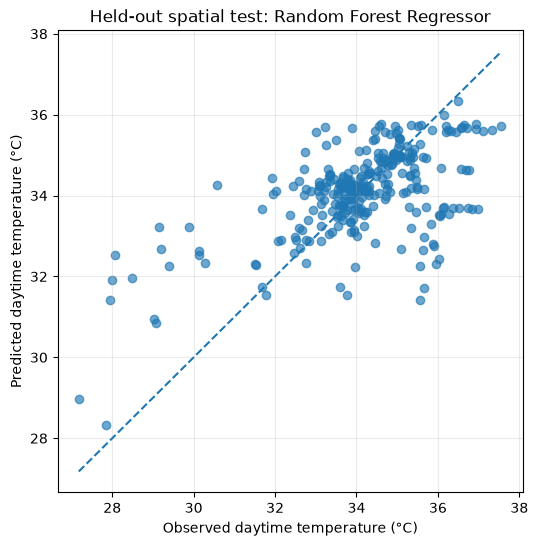

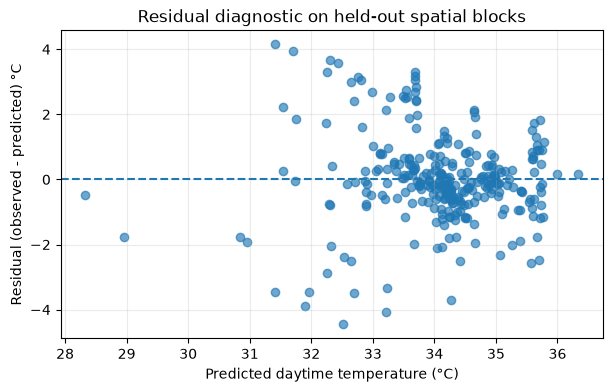

In [29]:
# Select the model with the lowest mean spatial-CV MAE.
best_algorithm_name = cv_results.iloc[0]["algorithm"]
best_regression_model = best_estimators[best_algorithm_name]

print("Selected algorithm from spatial CV:", best_algorithm_name)
print("Spatial CV MAE (°C):", round(float(cv_results.iloc[0]["spatial_cv_mae_c"]), 4))

# Evaluate the selected model on held-out spatial blocks.
test_predictions = best_regression_model.predict(X_test)

selected_test_mae = mean_absolute_error(y_test, test_predictions)
selected_test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
selected_test_r2 = r2_score(y_test, test_predictions)

# Compare with a simple mean-prediction baseline.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
baseline_test_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_test_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_test_r2 = r2_score(y_test, baseline_predictions)

evaluation = pd.DataFrame([
    {
        "model": best_algorithm_name,
        "test_MAE_C": selected_test_mae,
        "test_RMSE_C": selected_test_rmse,
        "test_R2": selected_test_r2
    },
    {
        "model": "Dummy mean baseline",
        "test_MAE_C": baseline_test_mae,
        "test_RMSE_C": baseline_test_rmse,
        "test_R2": baseline_test_r2
    }
])

display(evaluation.round(4))
evaluation.to_csv(OUTPUT_DIR / "modis_regression_holdout_evaluation.csv", index=False)

print("\nHeld-out spatial test set summary:")
print("Target mean (°C):", round(float(y_test.mean()), 3))
print("Target standard deviation (°C):", round(float(y_test.std()), 3))
print("Selected-model MAE (°C):", round(float(selected_test_mae), 3))
print("Baseline MAE (°C):", round(float(baseline_test_mae), 3))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_predictions, alpha=0.65)
min_value = min(y_test.min(), test_predictions.min())
max_value = max(y_test.max(), test_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Observed daytime temperature (°C)")
plt.ylabel("Predicted daytime temperature (°C)")
plt.title(f"Held-out spatial test: {best_algorithm_name}")
plt.grid(alpha=0.25)
plt.show()

residuals = y_test.to_numpy() - test_predictions
plt.figure(figsize=(7, 4))
plt.scatter(test_predictions, residuals, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted daytime temperature (°C)")
plt.ylabel("Residual (observed - predicted) °C")
plt.title("Residual diagnostic on held-out spatial blocks")
plt.grid(alpha=0.25)
plt.show()

## 11. Save a model candidate only if it improves on the baseline

The selected pipeline includes its own fitted `StandardScaler`, so the preprocessing needed at inference is packaged with the estimator. The model is saved as a **candidate for review**, not automatically approved for deployment.

A model is saved only if its held-out spatial-test MAE is lower than the DummyRegressor baseline. Deployment still requires review of source provenance, the exact use case, target availability at inference time, and the model's spatial generalisation.

In [30]:
import joblib

candidate_is_better_than_baseline = selected_test_mae < baseline_test_mae

candidate_dir = PROJECT_ROOT / "models/heat/modis"
candidate_dir.mkdir(parents=True, exist_ok=True)

if candidate_is_better_than_baseline:
    model_path = candidate_dir / "modis_daytime_temperature_regression_candidate.joblib"
    metadata_path = candidate_dir / "modis_daytime_temperature_regression_metadata.json"

    joblib.dump(best_regression_model, model_path)

    metadata = {
        "dataset": "Hyderabad MODIS Heat",
        "dataset_file": "hyderabad_modis_heat.csv",
        "target": TARGET_COLUMN,
        "features": REGRESSION_FEATURES,
        "task": "cross-variable estimation of measured daytime temperature; not forecasting",
        "selected_algorithm": best_algorithm_name,
        "spatial_block_degrees": SPATIAL_BLOCK_DEGREES,
        "spatial_cv_mae_c": float(cv_results.iloc[0]["spatial_cv_mae_c"]),
        "heldout_spatial_test_mae_c": float(selected_test_mae),
        "heldout_spatial_test_rmse_c": float(selected_test_rmse),
        "heldout_spatial_test_r2": float(selected_test_r2),
        "baseline_heldout_test_mae_c": float(baseline_test_mae),
        "candidate_saved": True,
        "deployment_approval": "pending scientific and integration review"
    }

    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

    print("Candidate model saved:", model_path)
    print("Metadata saved:", metadata_path)
else:
    print(
        "No model saved: the selected model did not beat the mean baseline "
        "on the held-out spatial test set. Review the experiment before deployment."
    )

Candidate model saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\heat\modis\modis_daytime_temperature_regression_candidate.joblib
Metadata saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\heat\modis\modis_daytime_temperature_regression_metadata.json


## 12. Optional exploratory classification: reproduce K-Means labels

The original notebook trained Logistic Regression, Decision Tree, Random Forest, KNN, SVM, and Gaussian Naive Bayes to predict three categories mapped from K-Means cluster IDs.

This section keeps a supervised-classifier comparison, but corrects the split order:

1. Hold out entire spatial blocks first.
2. Fit the K-Means scaler and K-Means model on training rows only.
3. Generate training cluster labels from that training-fitted K-Means model.
4. Assign test rows using the same fitted K-Means model.
5. Train classifiers to reproduce those cluster assignments.

**Interpretation:** the target is still generated by K-Means, not by independent heat-risk ground truth. The classifier scores describe how well classifiers imitate the K-Means partition. They must not be presented as real heat-risk classification accuracy or used as a validated risk model.

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

X_cluster = modis[spatial_thermal_features].copy()
X_cluster_train = X_cluster.iloc[train_indices].copy()
X_cluster_test = X_cluster.iloc[test_indices].copy()

# Fit K-Means preprocessing and cluster model on training data only.
cluster_label_scaler = StandardScaler()
X_cluster_train_scaled = cluster_label_scaler.fit_transform(X_cluster_train)
X_cluster_test_scaled = cluster_label_scaler.transform(X_cluster_test)

train_cluster_model = KMeans(
    n_clusters=7,
    n_init=10,
    random_state=RANDOM_STATE
)
y_cluster_train = train_cluster_model.fit_predict(X_cluster_train_scaled)
y_cluster_test = train_cluster_model.predict(X_cluster_test_scaled)

classifier_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(),
    "Gaussian Naive Bayes": GaussianNB()
}

classifier_results = []

for classifier_name, classifier in classifier_models.items():
    # Each classifier has its own scaler fitted only on training data.
    classifier_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])
    classifier_pipeline.fit(X_cluster_train, y_cluster_train)
    cluster_predictions = classifier_pipeline.predict(X_cluster_test)

    classifier_results.append({
        "algorithm": classifier_name,
        "cluster_label_accuracy": accuracy_score(y_cluster_test, cluster_predictions),
        "cluster_label_balanced_accuracy": balanced_accuracy_score(y_cluster_test, cluster_predictions),
        "cluster_label_weighted_f1": f1_score(
            y_cluster_test, cluster_predictions, average="weighted", zero_division=0
        )
    })

classifier_comparison = pd.DataFrame(classifier_results).sort_values(
    "cluster_label_weighted_f1", ascending=False
)
display(classifier_comparison)
classifier_comparison.to_csv(
    OUTPUT_DIR / "modis_kmeans_pseudolabel_classifier_comparison.csv",
    index=False
)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


,algorithm,cluster_label_accuracy,cluster_label_balanced_accuracy,cluster_label_weighted_f1
0,Logistic Regression,0.945763,0.953790,0.946418
4,SVM,0.942373,0.945550,0.944157
5,Gaussian Naive Bayes,0.942373,0.956132,0.942928
3,KNN,0.915254,0.918422,0.918596
2,Random Forest,0.894915,0.917144,0.894840
1,Decision Tree,0.844068,0.820626,0.839631


## 13. Final interpretation and deployment decision

Complete this section after reviewing the outputs.

### What can be reported

- K-Means identifies groups of samples with similar combinations of location and thermal measurements.
- Temperature-only clustering can be compared with spatial-plus-thermal clustering to understand the effect of coordinates.
- Regression can estimate the measured daytime temperature from the paired nighttime measurement and coordinates, provided it beats the baseline on held-out spatial blocks.
- The pseudo-label classifiers can be reported only as experiments that reproduce a K-Means partition.

### What must not be claimed from this dataset alone

- The K-Means clusters are not independently verified low/medium/high heat-risk labels.
- Pseudo-label classifier accuracy is not real-world heat-risk prediction accuracy.
- This dataset does not support a future-temperature forecast because the processed table has no date/time series.
- This notebook alone does not establish plot-level heat exposure or causal relationships.

### Before deployment

1. Review the selected regression model and compare it with the baseline.
2. Confirm the model's input variables will be available at inference time.
3. Confirm the MODIS data source, temporal coverage, units, and processing provenance.
4. Test model generalisation on an independent spatial area or newer observations if available.
5. Only then register a model run and integrate the candidate into the FastAPI application.

**No model is automatically marked deployment-ready by this notebook.**

In [32]:
print("Model exists:", model_path.exists())
print("Metadata exists:", metadata_path.exists())

print("\nSaved model:", model_path)
print("Saved metadata:", metadata_path)

if metadata_path.exists():
    print(json.loads(metadata_path.read_text(encoding="utf-8")))

Model exists: True
Metadata exists: True

Saved model: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\heat\modis\modis_daytime_temperature_regression_candidate.joblib
Saved metadata: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\heat\modis\modis_daytime_temperature_regression_metadata.json
{'dataset': 'Hyderabad MODIS Heat', 'dataset_file': 'hyderabad_modis_heat.csv', 'target': 'daytime_temp_c', 'features': ['latitude', 'longitude', 'nighttime_temp_c'], 'task': 'cross-variable estimation of measured daytime temperature; not forecasting', 'selected_algorithm': 'Random Forest Regressor', 'spatial_block_degrees': 0.04, 'spatial_cv_mae_c': 0.5057216703141942, 'heldout_spatial_test_mae_c': 0.9492512455488068, 'heldout_spatial_test_rmse_c': 1.359945230174111, 'heldout_spatial_test_r2': 0.35660668793927064, 'baseline_heldout_test_mae_c': 1.2048227344262619, 'candidate_saved': True, 'deployment_approval': 'pending scientific and integration review'}
